In [40]:
import numpy as np
from scipy.integrate import solve_ivp
from scipy.optimize import curve_fit
import matplotlib.pyplot as plt
# dCabydt = -k1*Ca
# dCbbydt = k1*Ca - k2*Cb 
# dCcbydt = k2*Cb


In [41]:
#Reactions in Series
Ca_in, Cb_in, Cc_in = 100, 0, 0
k1 = 0.1
k2 = 0.06
n1, n2 = 1, 1

In [51]:
def model1(t, Ca, k1):
    dCabydt = -k1*Ca
    return [dCabydt]

t_span = (0,10)
t_eval = np.linspace(0, 10, 100)
sol = solve_ivp(model1, t_span = t_span,y0 = [100], t_eval = t_eval, args=(k1,) )
time1 = sol.t
Ca = sol.y[0]
Ca

# Get Ca as a function of time 
def exp(x, a, b, c):
    return a + b*np.exp(c*x)
initial_guess = [0, 100, -2]
p_opt, p_cov = curve_fit(exp, time1, Ca, p0 = initial_guess)
a_opt, b_opt, c_opt = p_opt
p_opt
#Ca = 0.22 + 100*exp(-0.1*t)

array([ 0.22184971, 99.79124467, -0.10036708])

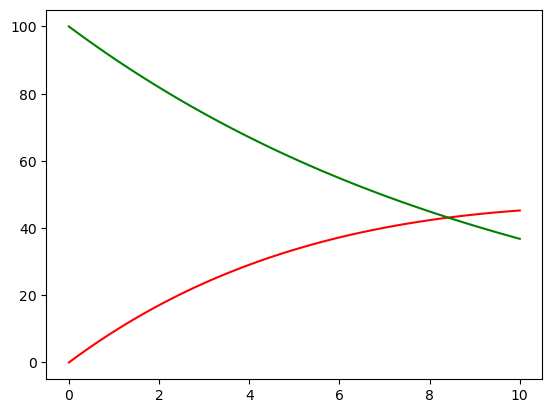

In [59]:
def model2(t, y, k1, k2):
    Cb = y[0]
    dCbbydt = k1*100*np.exp(-0.1*t) - k2*Cb 
    return [dCbbydt]
t_span = (0,10)
t_eval = np.linspace(0, 10, 100)
sol2 = solve_ivp(model2, t_span = t_span, y0 = [0], t_eval = t_eval, args=(k1,k2) )
time2 = sol2.t
Cb = sol2.y[0]
plt.plot(time2, Cb, 'r-')
plt.plot(time1, Ca, 'g-')
